# Compare PM2.5 forecasts on a shared test sample

English | [简体中文](model_test_comparison.zh-CN.ipynb)

Complete the [training notebook](model_training.ipynb) first. This notebook
loads the saved model checkpoints and samples origins uniformly without
replacement from the 3,818 origins in the reserved chronological test split.
Every model predicts the same sampled origins and the same six hourly targets.
The seed controls only the sampling. Rows are sorted by timestamp after sampling.
The training manifest verifies the matrix, checkpoints and implementation.

The tables show errors on the sampled origins in the original concentration
scale. Use `SAMPLE_COUNT = 3818` to score the entire test split. Use validation
results for model selection.

In [1]:
import sys

sys.dont_write_bytecode = True

import matplotlib.pyplot as plt
import numpy as np

from source.comparison import predict_comparison
from source.experiment_paths import CHECKPOINTS, MATRIX

TEST_SEED = 42
SAMPLE_COUNT = 512
RUN_DIR = CHECKPOINTS

sample, predictions, metrics = predict_comparison(
    MATRIX,
    RUN_DIR,
    seed=TEST_SEED,
    count=SAMPLE_COUNT,
)
print(f"{len(predictions)} configurations | seed={TEST_SEED}")
print(f"{len(sample.origins)} origins | {sample.actual.size} targets")
print(f"{sample.origins[0]} to {sample.origins[-1]} Singapore time")

24 configurations | seed=42
512 origins | 3072 targets
2024-06-11T18 to 2024-12-30T14 Singapore time


## Overall and per-horizon errors

In [2]:
ranking = sorted(metrics, key=lambda name: (metrics[name]["mse"], name))
print(f"{'Model':38s} {'MSE':>8s} {'RMSE':>8s} {'MAE':>8s}")
for name in ranking:
    score = metrics[name]
    print(
        f"{name:38s} {score['mse']:8.4f}"
        f" {score['rmse']:8.4f} {score['mae']:8.4f}"
    )
print()
print(f"{'Model':38s}", *(f"{f'h{hour}':>7s}" for hour in range(1, 7)))
for name in ranking:
    print(
        f"{name:38s}",
        *(f"{value:7.3f}" for value in metrics[name]["per_horizon_mse"]),
    )

Model                                       MSE     RMSE      MAE
catboost_variant_compact                18.0517   4.2487   3.2155
catboost_variant_lead_time_recent       18.2982   4.2776   3.2573
catboost_variant_trajectory_010         18.3359   4.2820   3.2598
catboost_variant_expanded_recent        18.3370   4.2822   3.2602
catboost_variant_trajectory_025         18.3623   4.2851   3.2574
blend_catboost_80_analog_20             18.3879   4.2881   3.2661
catboost_variant_original_recent        18.4527   4.2957   3.2451
catboost_east_depth6                    18.5234   4.3039   3.2203
catboost_east_depth4                    18.7869   4.3344   3.2317
catboost_variant_expanded_legacy        18.7870   4.3344   3.2935
catboost_variant_baseline_800           18.8579   4.3426   3.2739
catboost_variant_baseline_1200          18.8741   4.3444   3.2792
hgb_east_standard                       18.8928   4.3466   3.2578
catboost_five_depth6                    18.9083   4.3484   3.2810
hgb_east_r

## Six lowest sampled MSEs by horizon

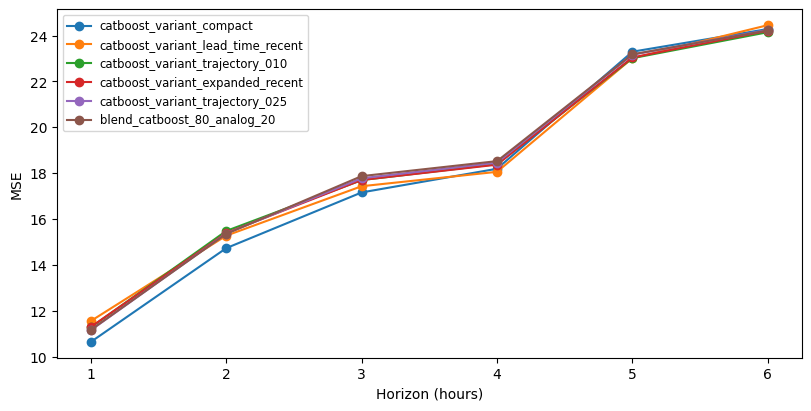

In [3]:
hours = np.arange(1, 7)
shown = ranking[:6]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for name in shown:
    ax.plot(hours, metrics[name]["per_horizon_mse"], "o-", label=name)
ax.set(xlabel="Horizon (hours)", ylabel="MSE", xticks=hours)
ax.legend(fontsize="small")
plt.show()

## Shared forecast examples

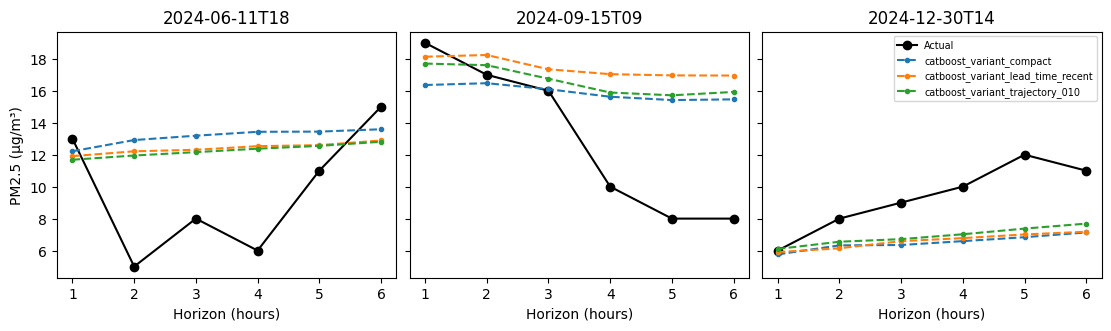

In [4]:
rows = np.unique(np.linspace(0, len(sample.origins) - 1, 3, dtype=int))
fig, axes = plt.subplots(
    1, len(rows), figsize=(11, 3.2), sharey=True, layout="constrained"
)
for ax, row in zip(np.atleast_1d(axes), rows):
    ax.plot(hours, sample.actual[row], "ko-", label="Actual")
    for name in shown[:3]:
        ax.plot(hours, predictions[name][row], ".--", label=name)
    ax.set(title=str(sample.origins[row]), xlabel="Horizon (hours)", xticks=hours)
np.atleast_1d(axes)[0].set_ylabel("PM2.5 (µg/m³)")
np.atleast_1d(axes)[-1].legend(fontsize="x-small")
plt.show()